In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Majority IQP versus a parameter-matched MLP

The IQP model is unchanged: 21 qubits in seven disjoint triples $B_j$.
Each triple applies Hadamards, three neural $R_Z(w_i^Ts+b_i)$ rotations,
three pair $R_{ZZ}$ gates, one $R_{ZZZ}$ gate, and final Hadamards.
All 21 output bits enter a single binary majority: action 0 for at most ten 1s.
The trainable parameter count is $21(4+1)+7(3+1)=133$.

**Why simulation is easy.** At fixed input $s$, there are no inter-block gates,
so $|\psi(s)\rangle=\bigotimes_{j=1}^7|\psi_j(s)\rangle$ and the seven
three-bit outcomes are independent. Compute each eight-outcome distribution
and let $q_j(r)=\Pr[|x_{B_j}|=r\mid s]$, $r=0,1,2,3$. Then
$$F(z)=\prod_{j=1}^7\sum_{r=0}^3q_j(r)z^r,\qquad
\pi(0\mid s)=\sum_{k=0}^{10}[z^k]F(z).$$
Successive convolution takes $O(n^2)$ arithmetic operations for $n$ qubits
partitioned into constant-size triples. Full bitstring sampling is also easy:
sample each three-bit block independently. The implementation uses equivalent
FFT convolution. This is exact factorization, up to numerical precision, not
a Fourier truncation. Exponential exact Pauli support does not prevent this
aggregate simulation. This is not the earlier connected random cubic graph.

**Matched baseline.** Linear(4,19) → Tanh → Linear(19,2), with softmax actions:
$4\cdot19+19+19\cdot2+2=135$ trainable parameters. Only the hidden width changes;
the initialization scheme, preprocessing, optimizer, learning rate, loss,
500-episode budget, 200-step cap and full-100-window freezing rule are unchanged.
Each seed receives 100 frozen-policy evaluation episodes.

The 20 IQP and smaller-MLP runs are reused without modification. This is a
requested follow-up on their cohort, not another independent confirmation of
the selected IQP model. No MLP-specific learning-rate tuning was performed.
Matching parameter count does not match expressivity or initialization.
The reported convergence metric is the first rolling-100 mean ≥195; runs that
never reach it within 500 episodes are assigned 501, not omitted.
Paired-bootstrap intervals and exact paired sign-randomization tests compare
IQP with the 135-parameter MLP. Holm correction covers the two primary endpoints.
These follow-up statistics do not remove the earlier architecture-selection bias.


In [1]:
from pathlib import Path
import json
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() / 'results' / 'majority_iqp_model_search'
result = json.loads((ROOT / 'parameter_matched_comparison.json').read_text())
rows = ['| Model | Parameters | AUC | Episodes to criterion | Held-out return | Solved |', '|---|---:|---:|---:|---:|---:|']
for name, r in result['summary'].items():
    rows.append(f"| {name} | {r['parameters']} | {r['auc']['mean']:.4f} | {r['restricted_solve_episode']['mean']:.1f} | {r['heldout']['mean']:.2f} | {r['solved_runs']}/20 |")
display(Markdown('\n'.join(rows)))

| Model | Parameters | AUC | Episodes to criterion | Held-out return | Solved |
|---|---:|---:|---:|---:|---:|
| iqpblocksbalanced_21_0.5 | 133 | 0.9256 | 174.6 | 198.13 | 20/20 |
| mlp | 65 | 0.8251 | 290.2 | 198.25 | 20/20 |
| mlp19 | 135 | 0.8475 | 278.1 | 191.00 | 16/20 |

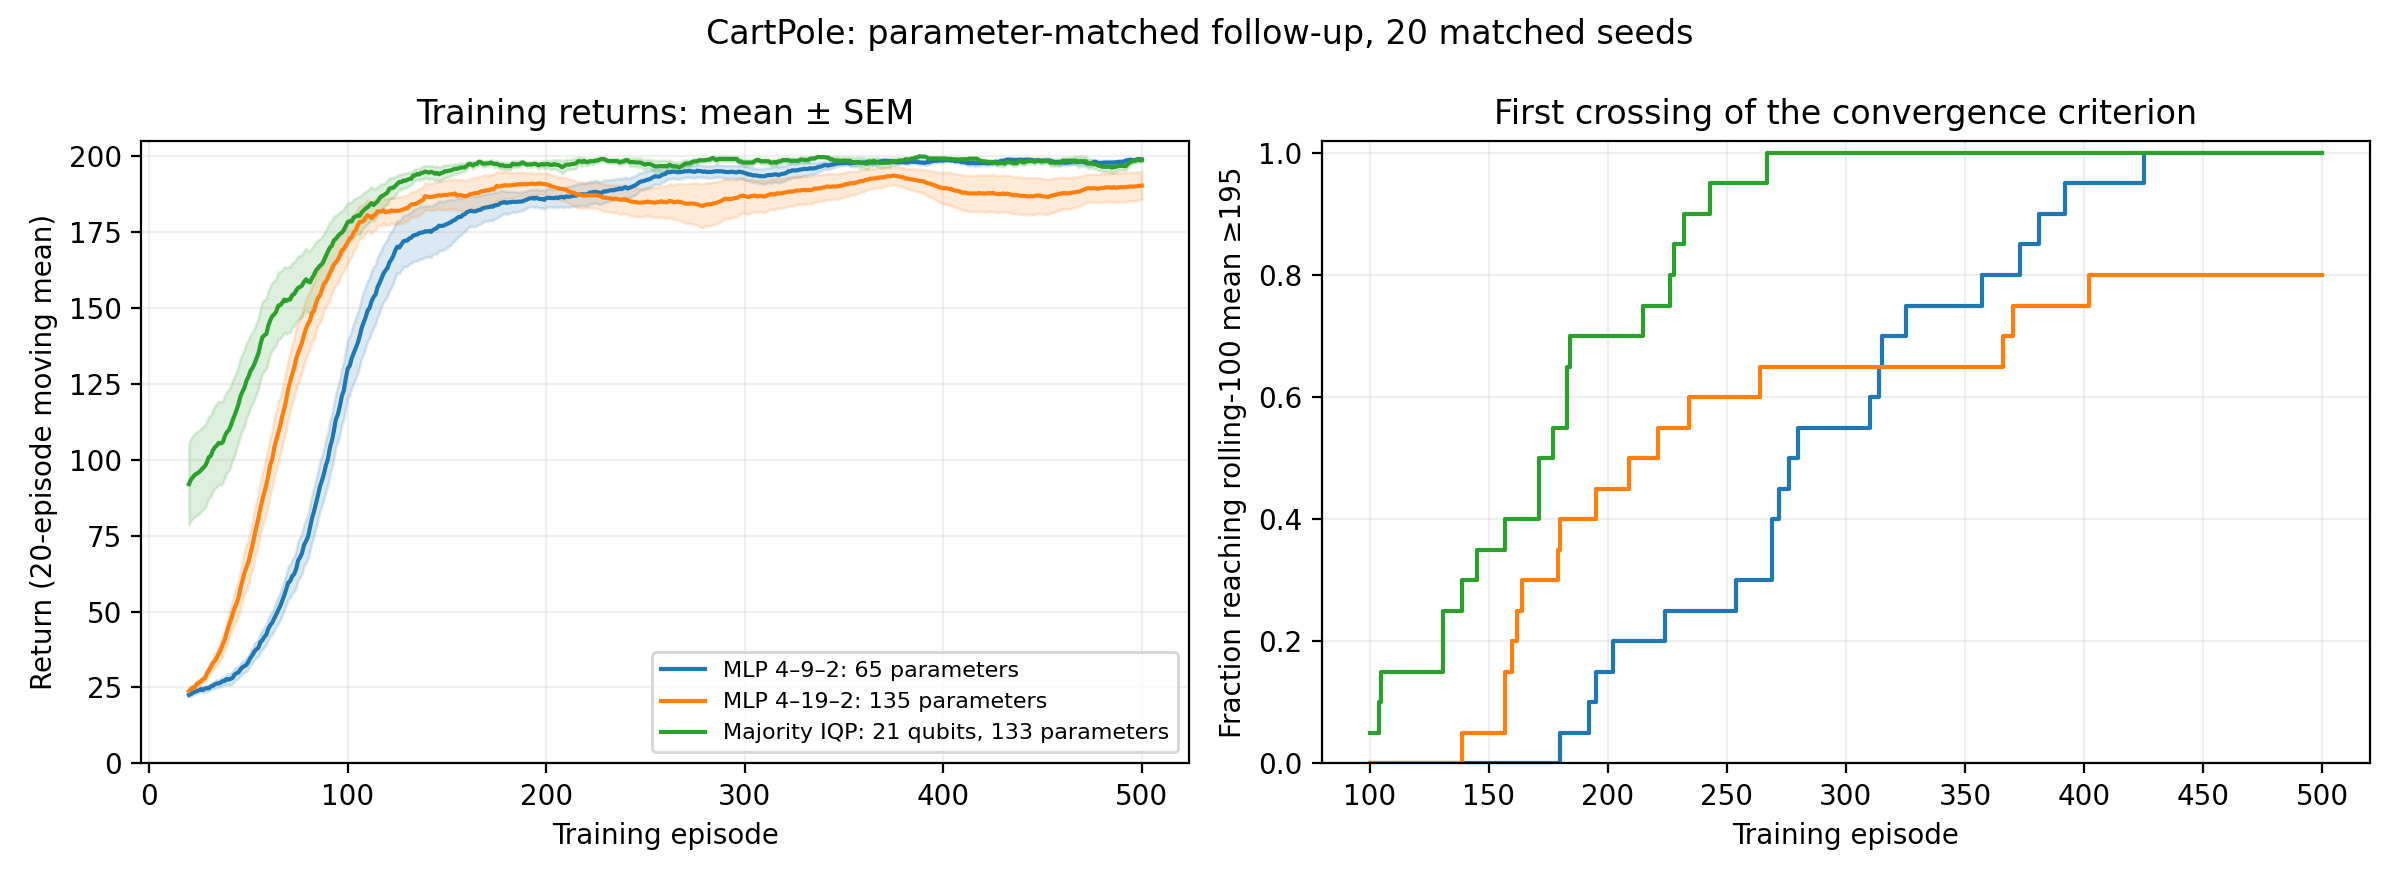

In [2]:
display(Image(filename=str(ROOT / 'parameter_matched_comparison.png')))

In [3]:
result['iqp_minus_matched_mlp']

{'auc': {'mean_difference': 0.078188,
  'ci95': [0.04558945, 0.108012525],
  'two_sided_exact_sign_p': 0.000377655029296875,
  'positive_pairs': 17,
  'holm_p': 0.00075531005859375},
 'restricted_solve_episode': {'mean_difference': 103.55,
  'ci95': [48.0, 161.25125000000008],
  'two_sided_exact_sign_p': 0.00273895263671875,
  'positive_pairs': 14,
  'holm_p': 0.00273895263671875},
 'final50': {'mean_difference': 8.145000000000005,
  'ci95': [-0.30399999999999644, 18.330000000000002],
  'two_sided_exact_sign_p': 0.13064193725585938,
  'positive_pairs': 10},
 'heldout': {'mean_difference': 7.1315,
  'ci95': [-0.053499999999999694, 16.428537499999997],
  'two_sided_exact_sign_p': 0.12378692626953125,
  'positive_pairs': 9}}

In [4]:
result['initial_return']

{'iqpblocksbalanced_21_0.5': 82.83349999999999,
 'mlp': 19.293000000000003,
 'mlp19': 21.2195}

## Reproduction

Run `majority_iqp_model_search.py run --phase validation_matched_strict --models mlp19`
with the 20 seeds in `matched_mlp_protocol.json`; then run
`audit_majority_initial_policy.py validation_matched_strict --jobs 3 --episodes 100`
and `analyze_matched_majority_comparison.py`. All raw returns and checkpoints
are retained. The analysis verifies return metrics, freezing and initialization.
The paper is unchanged.